In [1]:
# Set up google colab
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# Setup cell
import torch
import torch.nn as nn
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

%matplotlib inline
plt.rcParams["figure.figsize"] = (10.0, 8.0) # Set default size of plots
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gray"

In [3]:
# Load results
sarima = pd.read_csv("/content/drive/MyDrive/sarima_results.csv",
                     index_col=0, parse_dates=True)
lstm   = pd.read_csv("/content/drive/MyDrive/lstm_results.csv",
                     index_col=0, parse_dates=True)
slstm  = pd.read_csv("/content/drive/MyDrive/slstm_results.csv",
                     index_col=0, parse_dates=True)
sarima_long = pd.read_csv("/content/drive/MyDrive/sarima_long_results.csv",
                           index_col=0, parse_dates=True)
lstm_long   = pd.read_csv("/content/drive/MyDrive/lstm_long_results.csv",
                           index_col=0, parse_dates=True)
slstm_long  = pd.read_csv("/content/drive/MyDrive/slstm_long_results.csv",
                     index_col=0, parse_dates=True)

# Plotting

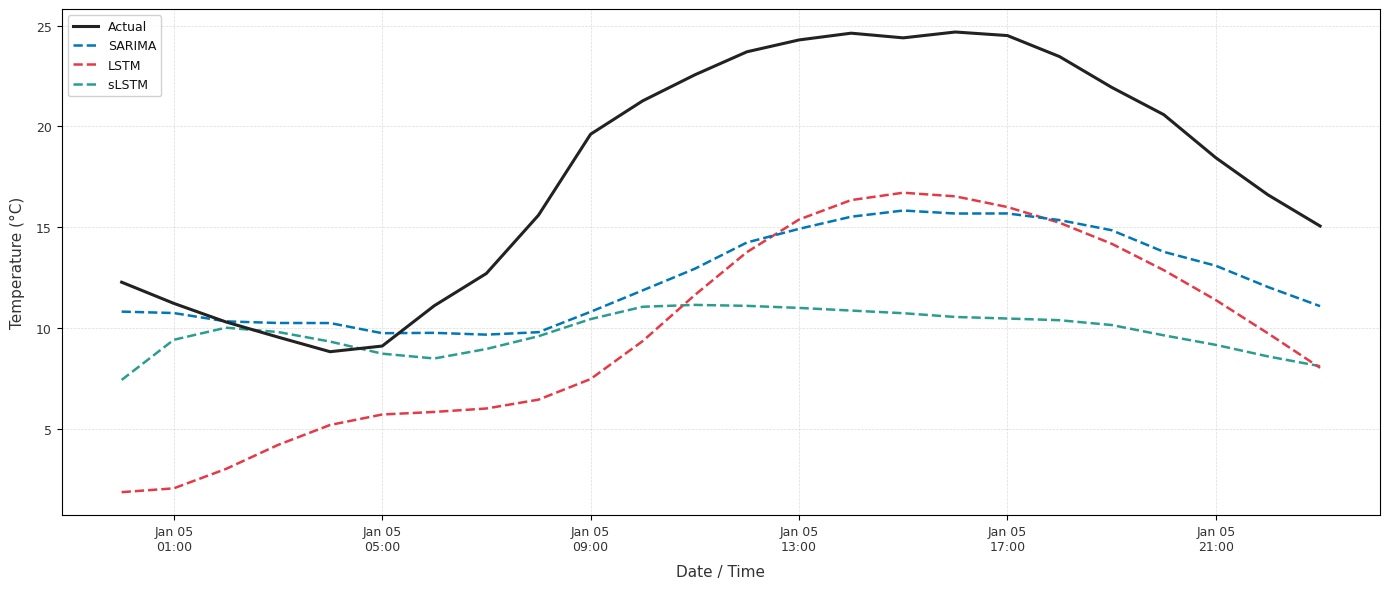

In [11]:
fig, ax = plt.subplots(figsize=(14, 6))

# Grid
ax.grid(color="#cccccc", linestyle="--", linewidth=0.5, alpha=0.7)
ax.set_axisbelow(True)

# Lines
ax.plot(sarima.index, sarima["actual"],
        color="#222222", linewidth=2.2,
        label="Actual", zorder=5)
ax.plot(sarima.index, sarima["forecast"],
        color="#0077b6", linewidth=1.8, linestyle="--",
        label="SARIMA", zorder=4)
ax.plot(lstm.index,   lstm["forecast"],
        color="#e63946", linewidth=1.8, linestyle="--",
        label="LSTM", zorder=3)
ax.plot(slstm.index,  slstm["forecast"],
        color="#2a9d8f", linewidth=1.8, linestyle="--",
        label="sLSTM ", zorder=2)

# Axis formatting
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d\n%H:%M"))
ax.xaxis.set_major_locator(mdates.HourLocator(interval=4))
plt.setp(ax.xaxis.get_majorticklabels(), color="#333333", fontsize=9)
plt.setp(ax.yaxis.get_majorticklabels(), color="#333333", fontsize=9)

# Labels
ax.set_xlabel("Date / Time", color="#333333", fontsize=11, labelpad=8)
ax.set_ylabel("Temperature (°C)", color="#333333", fontsize=11, labelpad=8)

# Legend
legend = ax.legend(
    loc="upper left",
    fontsize=9,
    framealpha=0.9,
    facecolor="white",
    edgecolor="#cccccc",
    labelcolor="#111111"
)

plt.tight_layout()
plt.show()

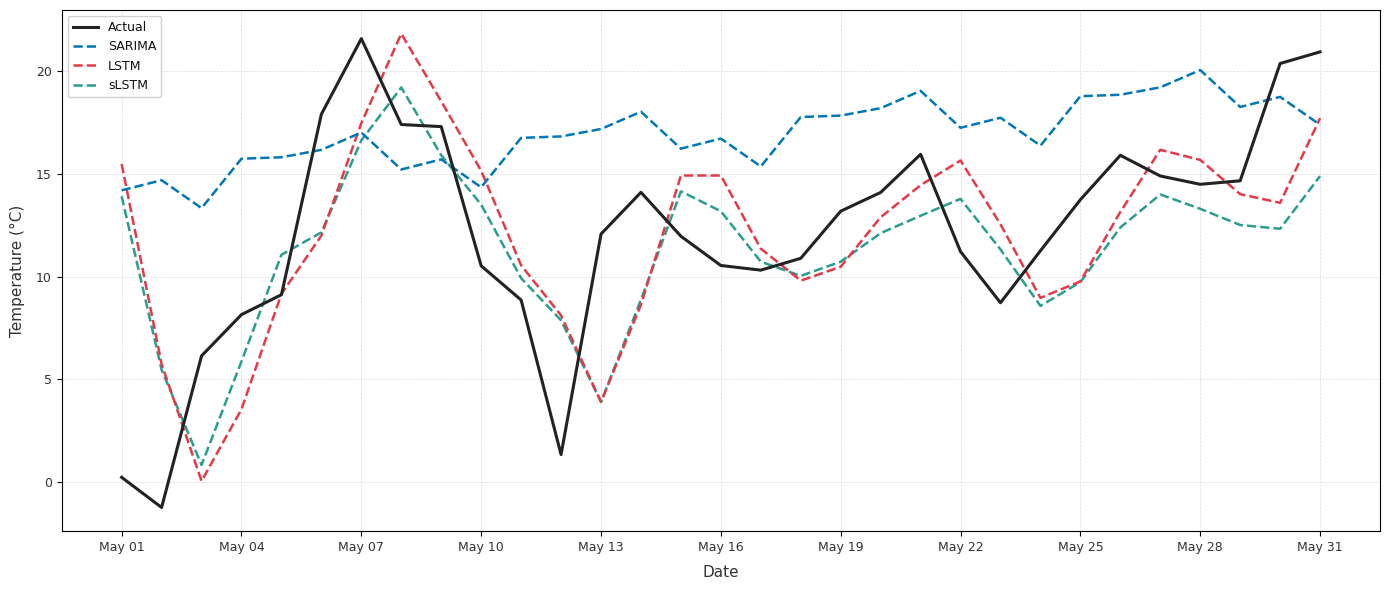

In [12]:
fig, ax = plt.subplots(figsize=(14, 6))

ax.grid(color="#cccccc", linestyle="--", linewidth=0.5, alpha=0.7)
ax.set_axisbelow(True)

ax.plot(sarima_long.index, sarima_long["actual"],
        color="#222222", linewidth=2.2,
        label="Actual", zorder=5)
ax.plot(sarima_long.index, sarima_long["forecast"],
        color="#0077b6", linewidth=1.8, linestyle="--",
        label="SARIMA", zorder=4)
ax.plot(lstm_long.index,   lstm_long["forecast"],
        color="#e63946", linewidth=1.8, linestyle="--",
        label="LSTM", zorder=3)
ax.plot(slstm_long.index,  slstm_long["forecast"],
        color="#2a9d8f", linewidth=1.8, linestyle="--",
        label="sLSTM", zorder=2)

ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.xaxis.set_major_locator(mdates.DayLocator(interval=3))
plt.setp(ax.xaxis.get_majorticklabels(), color="#333333", fontsize=9)
plt.setp(ax.yaxis.get_majorticklabels(), color="#333333", fontsize=9)

ax.set_xlabel("Date", color="#333333", fontsize=11, labelpad=8)
ax.set_ylabel("Temperature (°C)", color="#333333", fontsize=11, labelpad=8)

legend = ax.legend(
    loc="upper left",
    fontsize=9,
    framealpha=0.9,
    facecolor="white",
    edgecolor="#cccccc",
    labelcolor="#111111"
)

plt.tight_layout()
plt.show()

# Tables

In [14]:
from tabulate import tabulate
from IPython.display import display, HTML

In [15]:
# Helper function to get MAE and RMSE values from forecasting results
def get_metrics(actual, forecast):
    mae  = mean_absolute_error(actual, forecast)
    rmse = np.sqrt(mean_squared_error(actual, forecast))
    return round(mae, 3), round(rmse, 3)

# Obtain metric values
s_mae, s_rmse = get_metrics(sarima["actual"], sarima["forecast"])
l_mae, l_rmse = get_metrics(lstm["actual"],   lstm["forecast"])
sl_mae,sl_rmse= get_metrics(slstm["actual"],  slstm["forecast"])

sl_mae_l, sl_rmse_l   = get_metrics(sarima_long["actual"], sarima_long["forecast"])
l_mae_l,  l_rmse_l    = get_metrics(lstm_long["actual"],   lstm_long["forecast"])
sl_mae_ll,sl_rmse_ll  = get_metrics(slstm_long["actual"],  slstm_long["forecast"])

In [ ]:
results = pd.DataFrame({
    "Model": [
        "SARIMA",
        "LSTM",
        "sLSTM",
        "SARIMA (Long)",
        "LSTM (Long)",
        "sLSTM (Long)"
    ],
    "MAE": [
        s_mae,
        l_mae,
        sl_mae,
        sl_mae_l,
        l_mae_l,
        sl_mae_ll
    ],
    "RMSE": [
        s_rmse,
        l_rmse,
        sl_rmse,
        sl_rmse_l,
        l_rmse_l,
        sl_rmse_ll
    ]
})

print(results.to_latex(
    index=False,
    float_format="%.4f",
    caption="Forecasting Performance",
    label="tab:forecast_results"
))

\begin{table}
\caption{Forecasting Performance}
\label{tab:forecast_results}
\begin{tabular}{lrr}
\toprule
Model & MAE & RMSE \\
\midrule
SARIMA & 5.5410 & 6.5480 \\
LSTM & 7.9800 & 8.2750 \\
sLSTM & 8.0340 & 9.4430 \\
SARIMA (Long) & 5.7720 & 6.7890 \\
LSTM (Long) & 3.8980 & 4.9040 \\
sLSTM (Long) & 3.7160 & 4.6470 \\
\bottomrule
\end{tabular}
\end{table}

